## Reto Global Classroom – Analítica de Airbnb
## Grupo 3
### Etapa 2: Extracción, limpieza y transformación de datos


## 1) Carga de datos

Se importan las librerías necesarias y se carga el archivo original de Airbnb en formato CSV comprimido.


In [281]:
import pandas as pd
import numpy as np

df = pd.read_csv("../datos/listings.csv.gz")
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,19091,https://www.airbnb.com/rooms/19091,20260916052451,2026-09-17,NaN,Fully Furnished Cozy Apartment,This cozy space is a wonder of post-Katrina re...,NaN,https://a0.muscache.com/pictures/a5fdfd3b-5d81...,72880,...,4.97,4.70,4.91,"25-NSTR-11772, 25-OSTR-11151",NaN,1,1,0,0,2.75
1,71624,https://www.airbnb.com/rooms/71624,20260916052451,2026-09-17,NaN,Ravenwood Manor (Historic Bywater),You are in for a very unique stay in a neighbo...,NaN,https://a0.muscache.com/pictures/37488608/8cc1...,367223,...,4.98,4.84,4.89,"21-RSTR-18609, 22-OSTR-20720",NaN,1,1,0,0,1.67
2,74498,https://www.airbnb.com/rooms/74498,20260916052451,2026-09-17,NaN,Maison Marais 1,Maison Marais 1 is a stylish one-bedroom apart...,NaN,https://a0.muscache.com/pictures/73591836/a1f5...,391462,...,4.96,4.69,4.86,23-XSTR-13082,NaN,3,3,0,0,3.68
3,79536,https://www.airbnb.com/rooms/79536,20260916052451,2026-09-17,NaN,FeelAtHomeInNewOrleans-PrivateApt,"Safe, clean & comfortable!! Front porch and ga...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,428362,...,4.98,4.58,4.88,"23-NSTR-15067, 25-OSTR-41594",NaN,1,1,0,0,4.57
4,79609,https://www.airbnb.com/rooms/79609,20260916052451,2026-09-17,NaN,Bywater's Original & Finest,The Art of Hospitality,NaN,https://a0.muscache.com/pictures/5c5da2eb-7434...,428909,...,4.99,4.84,4.94,"23-ISTR-02823, 23-OSTR-02823",NaN,1,1,0,0,2.67



## 2) Exploración inicial de los datos

Se examina la estructura del conjunto de datos original para conocer su tamaño, identificar los tipos de variables y reconocer posibles problemas de calidad previo a iniciar la limpieza.


In [282]:
df.shape

(7263, 90)

In [283]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7263 entries, 0 to 7262
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            7263 non-null   int64  
 1   listing_url                                   7263 non-null   str    
 2   scrape_id                                     7263 non-null   int64  
 3   last_scraped                                  7263 non-null   str    
 4   source                                        935 non-null    str    
 5   name                                          7263 non-null   str    
 6   description                                   7256 non-null   str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   7263 non-null   str    
 9   host_id                                       7263 non-null   int64  
 10 

In [284]:
df.describe()

,id,scrape_id,neighborhood_overview,host_id,host_profile_id,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,7.263000e+03,7.263000e+03,0.0,7.263000e+03,7.263000e+03,0.0,7263.000000,7263.000000,7263.000000,7263.000000,...,6053.000000,6054.000000,6053.000000,6053.000000,0.0,7263.000000,7263.000000,7263.000000,7263.000000,6054.000000
mean,7.533297e+17,2.026092e+13,NaN,2.597130e+16,1.479065e+18,NaN,7.228143,5.631695,5.822250,5.876773,...,4.872599,4.863827,4.747157,4.719128,NaN,16.908302,12.953050,3.200193,0.005094,1.691805
std,6.497755e+17,0.000000e+00,NaN,2.094727e+17,4.625534e+16,NaN,4.195986,3.220438,3.980079,3.377447,...,0.298646,0.304546,0.342039,0.375887,NaN,27.589151,24.517551,10.825300,0.122408,2.110172
min,1.909100e+04,2.026092e+13,NaN,1.515700e+04,1.462507e+18,NaN,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.010000
25%,3.876836e+07,2.026092e+13,NaN,4.818777e+07,1.463106e+18,NaN,3.000000,3.000000,2.000000,3.000000,...,4.870000,4.860000,4.660000,4.670000,NaN,1.000000,1.000000,0.000000,0.000000,0.410000
50%,8.314493e+17,2.026092e+13,NaN,1.801774e+08,1.468139e+18,NaN,8.000000,6.000000,6.000000,6.000000,...,4.960000,4.960000,4.840000,4.810000,NaN,4.000000,2.000000,0.000000,0.000000,1.220000
75%,1.340809e+18,2.026092e+13,NaN,4.821747e+08,1.470173e+18,NaN,10.000000,8.000000,9.000000,9.000000,...,5.000000,5.000000,4.960000,4.910000,NaN,17.000000,12.000000,1.000000,0.000000,2.340000
max,1.774886e+18,2.026092e+13,NaN,1.762445e+18,1.771096e+18,NaN,17.000000,11.000000,15.000000,11.000000,...,5.000000,5.000000,5.000000,5.000000,NaN,128.000000,119.000000,71.000000,4.000000,42.170000


In [285]:
df.dtypes.value_counts()

float64    37
str        29
int64      24
Name: count, dtype: int64


## 3) Identificación de valores faltantes

Se analiza la presencia de valores faltantes en el conjunto de datos, identificando las variables afectadas y la proporción de información ausente. Este diagnóstico permitirá definir los procedimientos de limpieza adecuados.


In [286]:
df.isnull().sum()

id                                                 0
listing_url                                        0
scrape_id                                          0
last_scraped                                       0
source                                          6328
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               1209
Length: 90, dtype: int64

In [287]:
nulos = df.isnull().sum()
nulos[nulos > 0].sort_values(ascending=False)

host_since                      7263
neighborhood_overview           7263
host_thumbnail_url              7263
host_acceptance_rate            7263
host_response_rate              7263
host_response_time              7263
host_neighbourhood              7263
host_total_listings_count       7263
host_verifications              7263
neighbourhood                   7263
calendar_updated                7263
instant_bookable                7263
bathrooms                       7263
neighbourhood_group_cleansed    7263
source                          6328
host_about                      3140
host_location                   2411
license                         1451
review_scores_value             1210
review_scores_accuracy          1210
review_scores_checkin           1210
review_scores_location          1210
review_scores_rating            1209
first_review                    1209
review_scores_cleanliness       1209
reviews_per_month               1209
last_review                     1209
r

In [288]:
porcentaje_nulos = df.isnull().mean() * 100
porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False)

host_since                      100.000000
neighborhood_overview           100.000000
host_thumbnail_url              100.000000
host_acceptance_rate            100.000000
host_response_rate              100.000000
host_response_time              100.000000
host_neighbourhood              100.000000
host_total_listings_count       100.000000
host_verifications              100.000000
neighbourhood                   100.000000
calendar_updated                100.000000
instant_bookable                100.000000
bathrooms                       100.000000
neighbourhood_group_cleansed    100.000000
source                           87.126532
host_about                       43.232824
host_location                    33.195649
license                          19.977971
review_scores_value              16.659782
review_scores_accuracy           16.659782
review_scores_checkin            16.659782
review_scores_location           16.659782
review_scores_rating             16.646014
first_revie

In [289]:
df.columns[df.isnull().all()].tolist()

['neighborhood_overview',
 'host_since',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_thumbnail_url',
 'host_neighbourhood',
 'host_total_listings_count',
 'host_verifications',
 'neighbourhood',
 'neighbourhood_group_cleansed',
 'bathrooms',
 'calendar_updated',
 'instant_bookable']

In [290]:
resumen_nulos = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": df.isnull().mean() * 100
})

resumen_nulos[resumen_nulos["Cantidad"] > 0].sort_values(
    "Porcentaje", ascending=False
).round(2)

,Cantidad,Porcentaje
host_since,7263,100.00
neighborhood_overview,7263,100.00
host_thumbnail_url,7263,100.00
host_acceptance_rate,7263,100.00
host_response_rate,7263,100.00
host_response_time,7263,100.00
host_neighbourhood,7263,100.00
host_total_listings_count,7263,100.00
host_verifications,7263,100.00
neighbourhood,7263,100.00



### Interpretación de los valores faltantes

El análisis permite identificar las variables con información incompleta y aquellas que no contienen registros válidos. A partir de estos resultados se evaluará la pertinencia de cada variable para decidir si debe conservarse, eliminarse o recibir algún tratamiento. Las decisiones se tomarán considerando los objetivos de predicción de precios y clasificación de alojamientos.

Inicialmente el conjunto de datos cuenta con 7263 registros y 90 variables. Se identificaron 14 columnas las cuales están completamente vacías, además de 1073 registros sin precio que representa el 14.77% de faltantes para esta variable. También, identificamos columnas administrativas, identificadoras, enlaces y variables redundantes que no aportan información directa a los objetivos del proyecto. Por esta razón, se ropone eliminar las 14 columnas vacías y 9 variables administrativas, conservando principalmente aquellas que estan relacionadas con la ubicación, características físicas, comodidades, precio, anfitriones y calificaciones. Las variables parcialmente incompletas se evaluarán individualmente antes de aplicar metodos de imputación o elimar registros directamente.



## 4) Tratamiento de valores faltantes

Se realiza la limpieza de las variables identificadas en el análisis anterior, eliminando aquellas sin información o que no aportan directamente a los objetivos del proyecto. Las modificaciones se aplicarán sobre una copia del conjunto de datos original para conservar la información inicial.


In [291]:
df_limpio = df.copy()

In [292]:
df_limpio = df_limpio.dropna(axis=1, how="all")
df_limpio.shape

(7263, 76)

In [293]:
columnas_admin = [
    "listing_url", "scrape_id", "source",
    "host_url", "host_profile_id", "host_profile_url",
    "host_name", "host_picture_url", "picture_url"
]

In [294]:
df_limpio = df_limpio.drop(columns=columnas_admin)
df_limpio.shape

(7263, 67)

In [295]:
df_limpio["price"].head(10)

0    $139.00
1    $145.35
2    $146.77
3     $73.50
4     $55.23
5     $98.00
6    $354.36
7        NaN
8     $98.00
9     $93.67
Name: price, dtype: str

In [296]:
df_limpio["price"].dtype

<StringDtype(storage='python', na_value=nan)>

In [297]:
df_limpio["price"] = pd.to_numeric(
    df_limpio["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")

In [298]:
df_precio = df_limpio.dropna(subset=["price"]).copy()
df_precio.shape

(6190, 67)

In [299]:
df_limpio.isnull().sum().sort_values(ascending=False).head(20)

host_about                     3140
host_location                  2411
license                        1451
review_scores_location         1210
review_scores_checkin          1210
review_scores_value            1210
review_scores_accuracy         1210
first_review                   1209
review_scores_cleanliness      1209
reviews_per_month              1209
last_review                    1209
review_scores_rating           1209
review_scores_communication    1209
price_quote_price_per_night    1074
price_quote_total_price        1074
estimated_revenue_l365d        1073
price                          1073
price_quote_checkout_date       702
price_quote_checkin_date        702
price_quote_raw                 702
dtype: int64

In [300]:
nulos_restantes = df_precio.isnull().sum()
nulos_restantes[nulos_restantes > 0].sort_values(ascending=False)

host_about                     2727
host_location                  2154
license                        1083
review_scores_checkin           958
review_scores_accuracy          958
review_scores_location          958
review_scores_value             958
last_review                     957
first_review                    957
review_scores_communication     957
review_scores_cleanliness       957
reviews_per_month               957
review_scores_rating            957
beds                            186
minimum_nights                  126
maximum_nights                  126
maximum_maximum_nights          126
maximum_minimum_nights          126
minimum_minimum_nights          126
minimum_maximum_nights          126
bathrooms_text                  104
description                       3
price_quote_price_per_night       1
bedrooms                          1
price_quote_total_price           1
dtype: int64


### 4.1) Eliminación de variables de baja relevancia

Se retiran las variables relacionadas con información descriptiva del anfitrión y cotizaciones específicas que no se utilizarán en los modelos iniciales.


In [301]:
columnas_eliminar = ["host_about"]

df_precio = df_precio.drop(
    columns=columnas_eliminar,
    errors="ignore"
)

In [302]:
df_precio.shape

(6190, 66)

Selección de variables relevantes

Después de tratar los valores faltantes, el conjunto aún tiene 67 variables. Muchas no aportan al análisis posterior (predicción de precios y clasificación de alojamientos), por lo que se depuran con criterios explícitos y verificables:

1. **Sin información**: variables constantes o casi constantes (≥ 95 % de un mismo valor).
2. **Duplicadas o derivadas del precio**: generan fuga de información (*data leakage*) si se usa `price` como variable objetivo.
3. **Redundantes**: variables con correlación |r| ≥ 0.90 con otra, o que miden lo mismo con otra ventana de tiempo.
4. **Identificadores y texto libre**: no son utilizables directamente en un modelo.
5. **Transformables**: contienen información útil en un formato inadecuado (fechas, texto, listas). Se derivan variables nuevas y luego se elimina la original.

A partir de este punto se trabaja con `df_precio` (alojamientos con precio conocido), ya que sin precio no es posible entrenar ni evaluar modelos de precio.

In [303]:
import matplotlib.pyplot as plt
import seaborn as sns

df_sel = df_precio.copy()
df_sel.shape

(6190, 66)

In [304]:
resumen_var = pd.DataFrame({
    "n_unicos": df_sel.nunique(),
    "pct_valor_dominante": df_sel.apply(
        lambda s: s.value_counts(normalize=True).iloc[0] * 100)
}).round(2)

casi_constantes = resumen_var[resumen_var["pct_valor_dominante"] >= 95].sort_values(
    "pct_valor_dominante", ascending=False)
casi_constantes

,n_unicos,pct_valor_dominante
last_scraped,1,100.00
calendar_last_scraped,1,100.00
calculated_host_listings_count_shared_rooms,4,99.77
host_has_profile_pic,2,97.53
host_identity_verified,2,97.30
has_availability,2,97.22


derivadas del precio

Se comprueba si las variables `price_quote_*` y `estimated_revenue_l365d` reproducen el precio, lo que haría que el modelo "viera" la respuesta.

In [305]:
print("Coincidencia exacta price vs price_quote_price_per_night:",
      round((df_sel["price"] == df_sel["price_quote_price_per_night"]).mean() * 100, 2), "%")

# El ingreso estimado se calcula como ocupación estimada x precio
ocupados = df_sel[df_sel["estimated_occupancy_l365d"] > 0]
cociente = ocupados["estimated_revenue_l365d"] / (ocupados["estimated_occupancy_l365d"] * ocupados["price"])
print("estimated_revenue_l365d = ocupación x precio en el",
      round(np.isclose(cociente, 1, atol=0.01).mean() * 100, 2), "% de los casos")
print("Correlación price vs price_quote_total_price:",
      round(df_sel["price"].corr(df_sel["price_quote_total_price"]), 2))

Coincidencia exacta price vs price_quote_price_per_night: 99.98 %
estimated_revenue_l365d = ocupación x precio en el 100.0 % de los casos
Correlación price vs price_quote_total_price: 0.47


Variables redundantes por correlación

Se listan los pares de variables numéricas con |r| ≥ 0.90. En cada par se conserva la más interpretable o con menos nulos.

In [306]:
num = df_sel.select_dtypes(include="number").drop(columns=["id", "host_id"])
corr = num.corr()

pares = [(a, b, round(corr.loc[a, b], 3))
         for i, a in enumerate(corr.columns)
         for b in corr.columns[i + 1:]
         if abs(corr.loc[a, b]) >= 0.90]

pd.DataFrame(pares, columns=["variable_1", "variable_2", "correlacion"]).sort_values(
    "correlacion", ascending=False).reset_index(drop=True)

,variable_1,variable_2,correlacion
0,price,price_quote_price_per_night,1.000
1,minimum_nights,minimum_minimum_nights,1.000
2,maximum_nights,maximum_nights_avg_ntm,1.000
3,maximum_nights,maximum_maximum_nights,1.000
4,maximum_maximum_nights,maximum_nights_avg_ntm,1.000
5,minimum_nights,minimum_nights_avg_ntm,0.992
6,minimum_minimum_nights,minimum_nights_avg_ntm,0.992
7,availability_90,availability_eoy,0.985
8,availability_60,availability_90,0.970
9,availability_60,availability_eoy,0.939


Además de los pares anteriores, hay grupos de variables que miden lo mismo con distintas ventanas de tiempo. Se revisa su correlación con una variable de referencia.

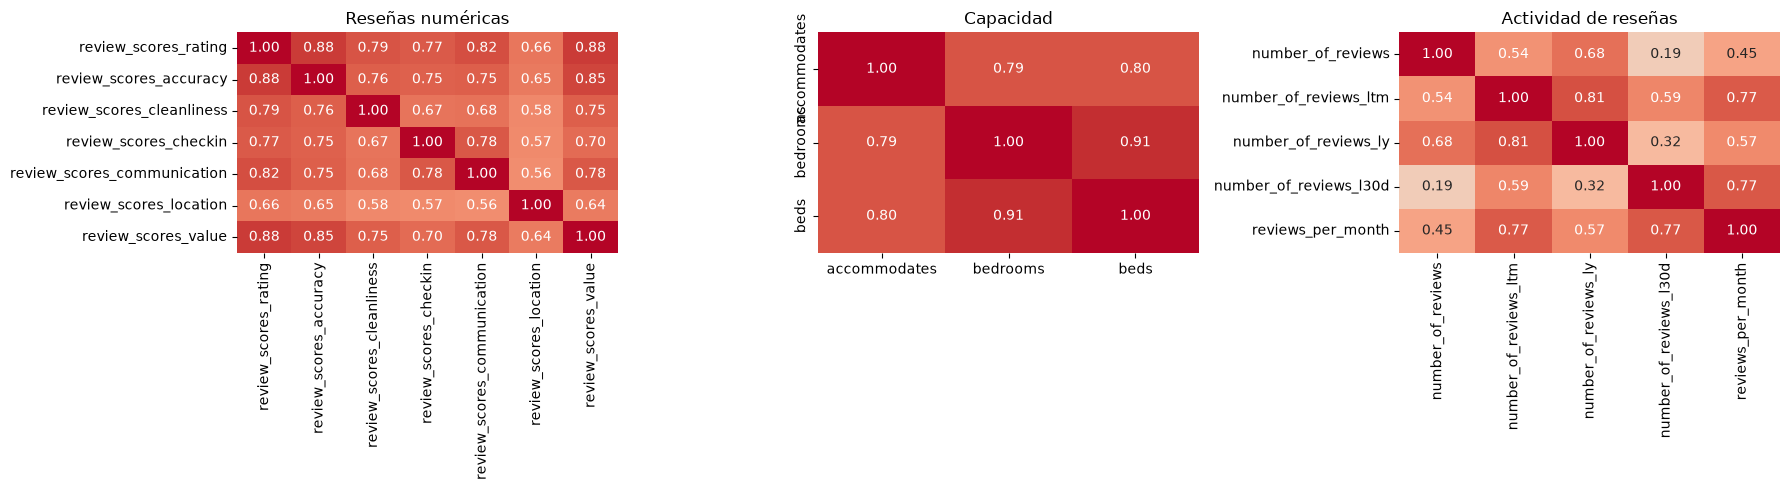

In [307]:
grupos = {
    "Reseñas numéricas": ["review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
                           "review_scores_checkin", "review_scores_communication",
                           "review_scores_location", "review_scores_value"],
    "Capacidad": ["accommodates", "bedrooms", "beds"],
    "Actividad de reseñas": ["number_of_reviews", "number_of_reviews_ltm",
                              "number_of_reviews_ly", "number_of_reviews_l30d", "reviews_per_month"],
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (titulo, cols) in zip(axes, grupos.items()):
    sns.heatmap(df_sel[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

Variables transformables

Algunas columnas guardan información útil en un formato que no se puede usar directamente. Se derivan variables nuevas y luego se elimina la original.

- **Licencia (`license`)**: el número de permiso es un identificador, pero tener o no licencia (o estar exento) sí puede influir en el precio. Se resume en una categoría.
- **Antigüedad del anfitrión**: los años y meses vienen en columnas separadas; se unifican en meses.
- **Fechas de reseña**: se pasan a formato fecha y se convierten en días transcurridos hasta la fecha de extracción.
- **Baños (`bathrooms_text`)**: se separa el número de baños y si son compartidos.
- **Comodidades (`amenities`)**: es una lista en texto; se resume en la cantidad de comodidades.

In [308]:
import json

# --- Licencia: sin licencia / exenta / con licencia
lic = df_sel["license"].astype(str).str.strip().str.lower()
df_sel["estado_licencia"] = np.select(
    [df_sel["license"].isnull(), lic == "exempt"],
    ["Sin licencia", "Exenta"],
    default="Con licencia"
)
print(df_sel["estado_licencia"].value_counts())
print()
print(df_sel.groupby("estado_licencia")["price"].median().round(2).rename("precio_mediano"))

estado_licencia
Con licencia    4939
Sin licencia    1083
Exenta           168
Name: count, dtype: int64

estado_licencia
Con licencia    227.50
Exenta          137.18
Sin licencia    102.04
Name: precio_mediano, dtype: float64


In [309]:
# --- Antigüedad del anfitrión (en meses)
df_sel["host_antiguedad_meses"] = (df_sel["hosts_time_as_host_years"] * 12
                                   + df_sel["hosts_time_as_host_months"])

# --- Fechas de reseña -> días hasta la fecha de extracción
df_sel["last_scraped"] = pd.to_datetime(df_sel["last_scraped"])
df_sel["first_review"] = pd.to_datetime(df_sel["first_review"])
df_sel["last_review"] = pd.to_datetime(df_sel["last_review"])

df_sel["dias_desde_primera_resena"] = (df_sel["last_scraped"] - df_sel["first_review"]).dt.days
df_sel["dias_desde_ultima_resena"] = (df_sel["last_scraped"] - df_sel["last_review"]).dt.days

df_sel[["host_antiguedad_meses", "dias_desde_primera_resena", "dias_desde_ultima_resena"]].describe().round(1)

,host_antiguedad_meses,dias_desde_primera_resena,dias_desde_ultima_resena
count,6190.0,5233.0,5233.0
mean,73.6,1583.7,240.7
std,47.9,1246.5,506.3
min,0.0,3.0,1.0
25%,32.0,574.0,16.0
50%,69.0,1294.0,46.0
75%,115.0,2515.0,166.0
max,188.0,5998.0,3912.0


In [310]:
# --- Baños: número y si es compartido
txt = df_sel["bathrooms_text"].astype("string").str.lower()

df_sel["banos"] = pd.to_numeric(txt.str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")
df_sel.loc[txt.str.contains("half", na=False) & df_sel["banos"].isnull(), "banos"] = 0.5
df_sel["banos_compartidos"] = txt.str.contains("shared", na=False).astype(int)

# --- Comodidades: cantidad
df_sel["n_comodidades"] = df_sel["amenities"].apply(
    lambda x: len(json.loads(x)) if isinstance(x, str) else 0)

df_sel[["bathrooms_text", "banos", "banos_compartidos", "n_comodidades"]].head(8)

,bathrooms_text,banos,banos_compartidos,n_comodidades
0,1 bath,1.0,0,52
1,1 bath,1.0,0,30
2,1 bath,1.0,0,39
3,1 bath,1.0,0,37
4,1 bath,1.0,0,46
5,2 shared baths,2.0,1,55
6,1 private bath,1.0,0,52
8,2 shared baths,2.0,1,60


Eliminación de variables y justificación

Se documenta cada variable eliminada junto con su motivo, de modo que la decisión quede trazable.

In [311]:
motivos = {}

def marcar(columnas, motivo):
    for c in columnas:
        motivos[c] = motivo

marcar(["host_id"], "Identificador sin valor analítico")
marcar(["name", "description", "host_about", "host_location"], "Texto libre no utilizable directamente")
marcar(["last_scraped", "calendar_last_scraped"], "Constante: misma fecha de extracción")
marcar(["calculated_host_listings_count_shared_rooms", "host_has_profile_pic",
        "host_identity_verified", "has_availability"], "Casi constante (≥ 95 % un solo valor)")
marcar(["price_quote_price_per_night", "price_quote_total_price", "price_quote_checkin_date",
        "price_quote_checkout_date", "price_quote_raw"], "Cotización del mismo precio: duplicada / fuga de información")
marcar(["estimated_revenue_l365d"], "Calculada a partir del precio: fuga de información")
marcar(["estimated_occupancy_l365d"], "Estimación calculada, no un dato observado")
marcar(["minimum_minimum_nights", "maximum_minimum_nights", "minimum_maximum_nights",
        "maximum_maximum_nights", "minimum_nights_avg_ntm", "maximum_nights_avg_ntm"],
       "Agregados de minimum_nights / maximum_nights (r ≈ 1)")
marcar(["availability_60", "availability_90", "availability_eoy"], "Redundante con availability_30 y availability_365 (r ≥ 0.93)")
marcar(["number_of_reviews_ltm", "number_of_reviews_ly", "number_of_reviews_l30d"],
       "Ventanas solapadas de number_of_reviews")
marcar(["review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin",
        "review_scores_communication", "review_scores_value"], "Correlacionada con review_scores_rating (r ≥ 0.77)")
marcar(["beds"], "Redundante con bedrooms (r ≈ 0.91) y con nulos")
marcar(["calculated_host_listings_count_entire_homes", "calculated_host_listings_count_private_rooms"],
       "Partición por tipo de alojamiento; ya está room_type")
marcar(["hosts_time_as_user_years", "hosts_time_as_user_months",
        "hosts_time_as_host_years", "hosts_time_as_host_months"], "Reemplazada por host_antiguedad_meses")
marcar(["first_review", "last_review"], "Reemplazada por días desde primera / última reseña")
marcar(["bathrooms_text"], "Reemplazada por banos y banos_compartidos")
marcar(["amenities"], "Reemplazada por n_comodidades")
marcar(["license"], "Reemplazada por estado_licencia")
marcar(["bathrooms_num", "bathroom_shared","bathroom_private", "bathrooms_imputado"],"Reemplazadas por banos y banos_compartidos"
)
tabla_motivos = pd.DataFrame(list(motivos.items()), columns=["variable_eliminada", "motivo"])
tabla_motivos

,variable_eliminada,motivo
0,host_id,Identificador sin valor analítico
1,name,Texto libre no utilizable directamente
2,description,Texto libre no utilizable directamente
3,host_about,Texto libre no utilizable directamente
4,host_location,Texto libre no utilizable directamente
5,last_scraped,Constante: misma fecha de extracción
6,calendar_last_scraped,Constante: misma fecha de extracción
7,calculated_host_listings_count_shared_rooms,Casi constante (≥ 95 % un solo valor)
8,host_has_profile_pic,Casi constante (≥ 95 % un solo valor)
9,host_identity_verified,Casi constante (≥ 95 % un solo valor)


In [312]:
df_sel = df_sel.drop(columns=list(motivos), errors="ignore")
df_sel = df_sel.set_index("id")
print("Variables eliminadas:", len(motivos))
print("Dimensiones finales:", df_sel.shape)

Variables eliminadas: 51
Dimensiones finales: (6190, 26)


Variables conservadas

Las variables que permanecen se agrupan por el rol que cumplen en el análisis posterior.

In [313]:
roles = {
    "Objetivo": ["price"],
    "Ubicación": ["neighbourhood_cleansed", "latitude", "longitude"],
    "Tipo y capacidad": ["property_type", "room_type", "accommodates", "bedrooms", "banos",
                         "banos_compartidos", "n_comodidades"],
    "Reglas de estadía": ["minimum_nights", "maximum_nights"],
    "Disponibilidad": ["availability_30", "availability_365"],
    "Reseñas": ["number_of_reviews", "reviews_per_month", "review_scores_rating",
                "review_scores_location", "dias_desde_primera_resena", "dias_desde_ultima_resena"],
    "Anfitrión": ["host_is_superhost", "host_listings_count", "calculated_host_listings_count",
                  "host_antiguedad_meses"],
    "Regulación": ["estado_licencia"],
    "Tipo y capacidad": ["property_type", "room_type", "bathroom_type","accommodates", "bedrooms", "banos","banos_compartidos", "n_comodidades"],
}

conservadas = pd.DataFrame([(g, c) for g, cols in roles.items() for c in cols],
                           columns=["grupo", "variable"])

# Verificación: todas las variables listadas existen y no falta ninguna
variables_no_clasificadas = [
    col for col in df_sel.columns
    if col not in conservadas["variable"].tolist()
]

print("Variables sin clasificar:", variables_no_clasificadas)

Variables sin clasificar: []


In [314]:
roles = {
    "Objetivo": ["price"],
    "Ubicación": ["neighbourhood_cleansed", "latitude", "longitude"],
    "Tipo y capacidad": ["property_type", "room_type", "accommodates", "bedrooms", "banos",
                         "banos_compartidos", "n_comodidades"],
    "Reglas de estadía": ["minimum_nights", "maximum_nights"],
    "Disponibilidad": ["availability_30", "availability_365"],
    "Reseñas": ["number_of_reviews", "reviews_per_month", "review_scores_rating",
                "review_scores_location", "dias_desde_primera_resena", "dias_desde_ultima_resena"],
    "Anfitrión": ["host_is_superhost", "host_listings_count", "calculated_host_listings_count",
                  "host_antiguedad_meses"],
    "Regulación": ["estado_licencia"],
}

conservadas = pd.DataFrame([(g, c) for g, cols in roles.items() for c in cols],
                           columns=["grupo", "variable"])

# Verificación: todas las variables listadas existen y no falta ninguna
assert set(conservadas["variable"]) == set(df_sel.columns), \
    set(df_sel.columns) ^ set(conservadas["variable"])

conservadas

,grupo,variable
0,Objetivo,price
1,Ubicación,neighbourhood_cleansed
2,Ubicación,latitude
3,Ubicación,longitude
4,Tipo y capacidad,property_type
5,Tipo y capacidad,room_type
6,Tipo y capacidad,accommodates
7,Tipo y capacidad,bedrooms
8,Tipo y capacidad,banos
9,Tipo y capacidad,banos_compartidos


### Decisión de la eliminación de datos faltantes


Decidimos excluir inicialmente la descripción del anfitrión y las variables de cotización directamente asociadas al precio, debido a su complejidad o redundancia frente a la variable objetivo. También, conservamos temporalmente las variables relacionadas con la ubicación del anfitrión, licencias y fechas de reserva, debido a su posible utilidad para generar nuevas características o desarrollar análisis complementarios.


### 4.2) Tratamiento de características físicas

Se revisan los valores faltantes en las variables relacionadas con las habitaciones, camas y baños de los alojamientos.


In [315]:
df_precio["beds"].value_counts(dropna=False).sort_index()

beds
1.0     1431
2.0     1723
3.0     1171
4.0      608
5.0      329
6.0      291
7.0      134
8.0      108
9.0       40
10.0      58
11.0      16
12.0      20
13.0      20
14.0      10
15.0       7
16.0       7
17.0       6
18.0       4
19.0       1
20.0       4
21.0       3
22.0       3
24.0       1
25.0       1
26.0       2
31.0       1
32.0       1
40.0       1
43.0       1
55.0       1
70.0       1
NaN      186
Name: count, dtype: int64

In [316]:
df_precio["bedrooms"].value_counts(dropna=False).sort_index()

bedrooms
0.0      176
1.0     2160
2.0     1799
3.0     1123
4.0      387
5.0      329
6.0       76
7.0       32
8.0       24
9.0       21
10.0      19
11.0       7
12.0       9
13.0       6
14.0       3
15.0       6
17.0       2
18.0       2
19.0       1
23.0       1
24.0       2
28.0       1
34.0       1
43.0       1
56.0       1
NaN        1
Name: count, dtype: int64

In [317]:
df_precio["bathrooms_text"].value_counts(dropna=False)

bathrooms_text
1 bath               2301
2 baths              1630
1 private bath        710
3 baths               352
2.5 baths             248
1.5 baths             200
4 baths               170
1 shared bath         106
NaN                   104
3.5 baths              91
5 baths                61
4.5 baths              45
2 shared baths         24
5.5 baths              20
6 baths                20
7 baths                19
1.5 shared baths       15
9 baths                 7
8 baths                 6
8.5 baths               6
0 baths                 5
10 baths                5
10.5 baths              4
7.5 baths               4
6.5 baths               4
11 baths                3
0 shared baths          3
9.5 baths               3
12 baths                3
2.5 shared baths        2
5 shared baths          2
18 baths                2
Private half-bath       2
14 baths                2
16 baths                2
16.5 baths              1
8.5 shared baths        1
13.5 baths             


### Imputación de habitaciones y camas

Se utiliza la mediana de alojamientos con características similares para completar los valores faltantes de "bedrooms" y "beds". La agrupación se realizó según el tipo de alojamiento y su capacidad, evitando utilizar un único valor para propiedades con características diferentes.


In [318]:
df_precio["bedrooms"] = df_precio["bedrooms"].fillna(
    df_precio.groupby(["room_type", "accommodates"])["bedrooms"].transform("median"))

In [319]:
df_precio["beds"] = df_precio["beds"].fillna(
    df_precio.groupby(["room_type", "accommodates"])["beds"].transform("median"))

In [320]:
df_precio[["bedrooms", "beds"]].isnull().sum()

bedrooms    0
beds        0
dtype: int64


### Transformación de la variable baños

La variable "bathrooms_text" contiene tanto la cantidad de baños como información sobre si son privados o compartidos. Se transforma en variables independientes para facilitar su utilización en los modelos predictivos.


In [321]:
df_precio["bathrooms_num"] = pd.to_numeric(
    df_precio["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce")

In [322]:
df_precio["bathroom_type"] = "No especificado"

df_precio.loc[
    df_precio["bathrooms_text"].str.contains("shared", case=False, na=False),
    "bathroom_type"] = "Compartido"

df_precio.loc[
    df_precio["bathrooms_text"].str.contains("private", case=False, na=False),
    "bathroom_type"] = "Privado"

df_precio.loc[
    df_precio["bathrooms_text"].isna(),
    "bathroom_type"] = "Desconocido"

df_precio["bathroom_type"].value_counts()

bathroom_type
No especificado    5217
Privado             712
Compartido          157
Desconocido         104
Name: count, dtype: int64

In [323]:
df_precio["bathroom_shared"] = (
    df_precio["bathrooms_text"].str.contains("shared", case=False, na=False).astype(int))

In [324]:
df_precio["bathroom_private"] = (
    df_precio["bathrooms_text"].str.contains("private", case=False, na=False).astype(int))

In [325]:
df_precio["bathrooms_num"].isnull().sum()

np.int64(106)


### Interpretación

Ya que las variables físicas presentan una proporción relativamente baja de datos faltantes, proponemos imputar habitaciones y camas mediante la mediana de alojamientos similares, agrupados por tipo de habitación y capacidad. Consecuentemente, la variable de baños se transforma para separar su cantidad numérica de las características de uso compartido o privado. También, identificamos alojamientos con cantidades elevadas de habitaciones, camas y baños. Estos valores se conservarán temporalmente para analizarlos posteriormente durante el tratamiento de valores atípicos.


In [326]:
df_precio["bathrooms_imputado"] = (
    df_precio["bathrooms_num"].isna().astype(int))

In [327]:
df_precio["bathrooms_num"] = df_precio["bathrooms_num"].fillna(
    df_precio.groupby(["room_type", "bedrooms"])["bathrooms_num"].transform("median"))

In [328]:
df_precio["bathrooms_num"].isnull().sum()

np.int64(75)

In [329]:
df_precio[["bedrooms", "beds", "bathrooms_num"]].isnull().sum()

bedrooms          0
beds              0
bathrooms_num    75
dtype: int64

In [330]:
df_precio[
    ["bedrooms", "beds", "bathrooms_num", "bathroom_type"]].head(10)

,bedrooms,beds,bathrooms_num,bathroom_type
0,1.0,1.0,1.0,No especificado
1,1.0,1.0,1.0,No especificado
2,1.0,2.0,1.0,No especificado
3,1.0,2.0,1.0,No especificado
4,2.0,2.0,1.0,No especificado
5,1.0,1.0,2.0,Compartido
6,1.0,2.0,1.0,Privado
8,1.0,1.0,2.0,Compartido
9,2.0,2.0,2.5,No especificado
10,2.0,2.0,2.5,No especificado



### Tratamiento de las condiciones de reserva

Se analizan las variables "minimum_nights" y "maximum_nights", que representan los límites de duración de las reservas. Debido a que estas condiciones pueden estar relacionadas con el precio y el tipo de alojamiento, se revisarán sus distribuciones y valores faltantes antes de definir un procedimiento de imputación.


In [331]:
df_precio[["minimum_nights", "maximum_nights"]].describe()

,minimum_nights,maximum_nights
count,6064.000000,6.064000e+03
mean,11.632091,4.604354e+06
std,17.476537,9.933256e+07
min,1.000000,3.000000e+00
25%,1.000000,3.650000e+02
50%,2.000000,3.650000e+02
75%,30.000000,1.125000e+03
max,365.000000,2.147484e+09


In [332]:
df_precio["minimum_nights"].value_counts(dropna=False).head(15)

minimum_nights
1.0      2243
30.0     1924
2.0      1556
3.0       210
NaN       126
31.0       44
60.0       32
4.0        15
90.0        8
5.0         5
365.0       4
7.0         3
32.0        3
29.0        2
14.0        2
Name: count, dtype: int64

In [333]:
df_precio["maximum_nights"].value_counts(dropna=False).head(15)

maximum_nights
365.0     2378
1125.0    2097
30.0       245
90.0       145
45.0       141
NaN        126
180.0      119
730.0       98
60.0        88
120.0       66
28.0        66
731.0       56
14.0        50
7.0         43
29.0        41
Name: count, dtype: int64

In [334]:
(df_precio["minimum_nights"] > df_precio["maximum_nights"]).sum()

np.int64(0)

In [335]:
(df_precio[["minimum_nights", "maximum_nights"]] <= 0).sum()

minimum_nights    0
maximum_nights    0
dtype: int64

In [336]:
df_precio["minimum_nights_imputado"] = df_precio["minimum_nights"].isna().astype(int)
df_precio["maximum_nights_imputado"] = df_precio["maximum_nights"].isna().astype(int)

In [337]:
df_precio["minimum_nights"] = df_precio["minimum_nights"].fillna(
    df_precio.groupby(["room_type", "property_type"])["minimum_nights"].transform("median"))

In [338]:
df_precio["maximum_nights"] = df_precio["maximum_nights"].fillna(
    df_precio.groupby(["room_type", "property_type"])["maximum_nights"].transform("median"))

In [339]:
df_precio[["minimum_nights", "maximum_nights"]].isnull().sum()

minimum_nights    0
maximum_nights    0
dtype: int64


### Tratamiento de reseñas y calificaciones

Se identificaron 957 alojamientos sin calificación general, equivalentes al 15,46 % de los registros. Mediante una tabla cruzada se comprobó que estos alojamientos coinciden exactamente con aquellos que no tienen reseñas. Por esta razón, se decidió no imputar las calificaciones, ya que su ausencia responde a la falta de evaluaciones y no necesariamente a errores en los datos.


In [340]:
pd.crosstab(
    df_precio["number_of_reviews"] == 0,
    df_precio["review_scores_rating"].isna())

review_scores_rating,False,True
number_of_reviews,,
False,5233,0
True,0,957


### Evaluación de relevancia de las calificaciones

Se analiza la relación entre las siete variables de calificación para identificar posibles redundancias y evaluar su utilidad en los modelos predictivos.

In [341]:
calificaciones = [
    "review_scores_rating", "review_scores_accuracy",
    "review_scores_cleanliness", "review_scores_checkin",
    "review_scores_communication", "review_scores_location",
    "review_scores_value"]

In [342]:
df_precio[calificaciones].corr().round(2)

,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
review_scores_rating,1.00,0.88,0.79,0.77,0.82,0.66,0.88
review_scores_accuracy,0.88,1.00,0.76,0.75,0.75,0.65,0.85
review_scores_cleanliness,0.79,0.76,1.00,0.67,0.68,0.58,0.75
review_scores_checkin,0.77,0.75,0.67,1.00,0.78,0.57,0.70
review_scores_communication,0.82,0.75,0.68,0.78,1.00,0.56,0.78
review_scores_location,0.66,0.65,0.58,0.57,0.56,1.00,0.64
review_scores_value,0.88,0.85,0.75,0.70,0.78,0.64,1.00


In [343]:
df_precio[calificaciones].describe().round(2)

,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
count,5233.00,5232.00,5233.00,5232.00,5233.00,5232.00,5232.00
mean,4.78,4.81,4.80,4.87,4.86,4.75,4.72
std,0.36,0.34,0.33,0.31,0.30,0.35,0.38
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,4.73,4.78,4.75,4.87,4.85,4.66,4.67
50%,4.88,4.91,4.89,4.95,4.95,4.84,4.81
75%,4.97,4.98,4.98,5.00,5.00,4.96,4.91
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00



### Tratamiento de fechas y frecuencia de reseñas

Se revisan las variables "first_review", "last_review" y "reviews_per_month" para comprobar si sus valores faltantes corresponden a alojamientos sin historial de evaluaciones.


In [344]:
df_precio["first_review"] = pd.to_datetime(
    df_precio["first_review"], errors="coerce")

df_precio["last_review"] = pd.to_datetime(
    df_precio["last_review"], errors="coerce")

In [345]:
df_precio[["first_review", "last_review"]].dtypes

first_review    datetime64[us]
last_review     datetime64[us]
dtype: object

In [346]:
df_precio["reviews_per_month"] = df_precio[
    "reviews_per_month"].fillna(0)

### Interpretación

Las fechas se transformaron a un formato temporal consistente. En los alojamientos sin evaluaciones, estas fechas se conservarán como desconocidas, evitando asignar información ficticia. Para la frecuencia mensual de reseñas, se contempla utilizar el valor cero únicamente cuando se confirme que el alojamiento no tiene evaluaciones registradas.

In [347]:
nulos_finales = df_precio.isnull().sum()
nulos_finales[nulos_finales > 0].sort_values(ascending=False)

host_location                  2154
license                        1083
review_scores_checkin           958
review_scores_accuracy          958
review_scores_value             958
review_scores_location          958
first_review                    957
review_scores_cleanliness       957
review_scores_communication     957
last_review                     957
review_scores_rating            957
minimum_minimum_nights          126
minimum_maximum_nights          126
maximum_maximum_nights          126
maximum_minimum_nights          126
bathrooms_text                  104
bathrooms_num                    75
description                       3
price_quote_total_price           1
price_quote_price_per_night       1
dtype: int64

In [348]:
porcentaje = df_precio.isnull().mean() * 100
porcentaje[porcentaje > 0].sort_values(ascending=False).round(2)

host_location                  34.80
license                        17.50
review_scores_checkin          15.48
review_scores_accuracy         15.48
review_scores_value            15.48
review_scores_location         15.48
first_review                   15.46
review_scores_cleanliness      15.46
review_scores_communication    15.46
last_review                    15.46
review_scores_rating           15.46
minimum_minimum_nights          2.04
minimum_maximum_nights          2.04
maximum_maximum_nights          2.04
maximum_minimum_nights          2.04
bathrooms_text                  1.68
bathrooms_num                   1.21
description                     0.05
price_quote_total_price         0.02
price_quote_price_per_night     0.02
dtype: float64

In [349]:
df_precio.shape

(6190, 73)

In [350]:
df_final = df_sel.reset_index().copy()
df_final["bathroom_type"] = df_precio["bathroom_type"]

In [351]:
columnas_redundantes = [
    "minimum_minimum_nights", "maximum_minimum_nights",
    "minimum_maximum_nights", "maximum_maximum_nights",
    "minimum_nights_avg_ntm", "maximum_nights_avg_ntm"]

df_final = df_final.drop(columns=columnas_redundantes, errors="ignore")

In [352]:
df_final["rating_disponible"] = df_final["review_scores_rating"].notna().astype(int)

In [353]:
calificaciones_finales = [
    col for col in calificaciones
    if col in df_final.columns
]

df_final[calificaciones_finales] = (
    df_final[calificaciones_finales].fillna(-1)
)

In [354]:
numericas = df_final.select_dtypes(include="number").columns
df_final[numericas] = df_final[numericas].fillna(df_final[numericas].median())

In [355]:
categoricas = df_final.select_dtypes(include="object").columns
df_final[categoricas] = df_final[categoricas].fillna("Desconocido")

C:\Users\jsqo4\AppData\Local\Temp\ipykernel_7288\2623420134.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df_final.select_dtypes(include="object").columns


In [356]:
fechas = df_final.select_dtypes(include="datetime").columns
df_final = df_final.drop(columns=fechas)

In [357]:
df_final.isnull().sum().sum()

np.int64(0)

In [358]:
df_final.shape

(6190, 29)


## 5) Identificación y eliminación de duplicados

Se verifica la existencia de registros duplicados y de identificadores repetidos para evitar que un mismo alojamiento aparezca varias veces en el análisis.


In [359]:
df_final.duplicated().sum()

np.int64(0)

In [360]:
df_final["id"].duplicated().sum()

np.int64(0)

In [361]:
df_final = df_final.drop_duplicates(subset="id")
df_final.shape

(6190, 29)


### Interpretación

Se revisaron los registros duplicados y los identificadores repetidos. Se conservaron observaciones únicas por alojamiento para evitar duplicidades en los análisis y modelos posteriores.



## 6. Estandarización y codificación de variables

Se revisan los formatos de las variables categóricas y se genera una versión codificada de los datos para facilitar su utilización en los modelos predictivos.


In [362]:
df_final[["room_type", "property_type", "bathroom_type"]].nunique()

room_type         4
property_type    44
bathroom_type     4
dtype: int64

In [363]:
columnas_cat = ["room_type", "property_type", "bathroom_type"]

df_final[columnas_cat] = df_final[columnas_cat].apply(
    lambda x: x.str.strip())

In [364]:
df_modelo = pd.get_dummies(
    df_final, columns=columnas_cat, dtype=int)


### Interpretación

Se estandarizaron las categorías relacionadas con el tipo de propiedad, habitación y baño. Posteriormente, se utilizó codificación one-hot para representar estas características mediante variables binarias.



## 7. Identificación y tratamiento de valores atípicos

Se analizan los valores extremos de las variables numéricas, especialmente del precio y las características físicas de los alojamientos.


In [365]:
df_final["price"].describe()

count     6190.000000
mean       282.805806
std        405.308573
min         20.070000
25%        126.650000
50%        197.280000
75%        315.247500
max      14909.720000
Name: price, dtype: float64

In [366]:
Q1 = df_final["price"].quantile(0.25)
Q3 = df_final["price"].quantile(0.75)
IQR = Q3 - Q1

In [367]:
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df_final["precio_atipico"] = (
    (df_final["price"] < limite_inferior) |
    (df_final["price"] > limite_superior)).astype(int)

In [368]:
df_final["precio_atipico"].value_counts()

precio_atipico
0    5728
1     462
Name: count, dtype: int64


### Interpretación de los valores atípicos

Mediante el método del rango intercuartílico (IQR), se identificaron 462 alojamientos con precios atípicos, equivalentes al 7,46 % de los 6.190 registros analizados. Se decidió conservar estos registros y crear la variable "precio_atipico", debido a que los precios elevados podrían corresponder a propiedades con características particulares.



## 8) Validación y exportación de datos

Se verifica la integridad del conjunto de datos y se exportan las versiones preparadas para los análisis exploratorios y modelos predictivos.


In [369]:
df_final.isnull().sum().sum()

np.int64(0)

In [370]:
df_final.shape

(6190, 30)

In [371]:
from pathlib import Path

Path("../resultados").mkdir(parents=True, exist_ok=True)

In [372]:
df_final.to_csv("../resultados/new_orleans_limpio.csv", index=False)
df_modelo.to_csv("../resultados/new_orleans_modelo.csv", index=False)